# UTS Graf Sains Data

## 1. Tugas Pendahuluan

### 1.1 Persiapan dan Perkenalan Lingkungan

Pada tahap awal, saya menyiapkan lingkungan Python untuk pengerjaan UTS Graf Sains Data. Saya menggunakan Python versi 3.10.11 dan membuat virtual environment dengan nama `.venv` agar library yang digunakan pada tugas ini terpisah dari proyek Python lainnya.

Pengerjaan dilakukan menggunakan Windows PowerShell. Saya membuat file `requirements.txt` sesuai daftar dependensi pada soal, kemudian menginstalnya menggunakan pip. Setelah instalasi selesai, saya menjalankan `pip check` dan memperoleh hasil `No broken requirements found`.

Saya juga menginstal Jupyter Notebook dan ipykernel untuk mengerjakan serta mendokumentasikan seluruh tahapan UTS dalam file `.ipynb`.

Selanjutnya, saya memeriksa folder kerja, versi Python, dan lokasi interpreter untuk memastikan notebook sudah menggunakan virtual environment yang sesuai.

In [1]:
import os
import sys

print("Folder kerja:", os.getcwd())
print("Versi Python:", sys.version.split()[0])
print("Lokasi Python:", sys.executable)

Folder kerja: D:\SEMESTER 7\GRAF SAINS DATA\UTS
Versi Python: 3.10.11
Lokasi Python: D:\SEMESTER 7\GRAF SAINS DATA\UTS\.venv\Scripts\python.exe


### 1.2 Mempelajari Penggunaan Driver Neo4j

Pada tahap ini, saya mencoba menggunakan Python Driver untuk mengakses database Neo4j. Saya menggunakan instance `uts-graf-sains-data` dan database `neo4j` yang dijalankan secara lokal melalui Neo4j Desktop.

Sebelum membuat graf, saya menguji koneksi Python ke Neo4j menggunakan query `RETURN 1 AS hasil`. Pengujian tersebut berhasil dan menghasilkan nilai `1`, sehingga koneksi dapat digunakan.

Selanjutnya, saya mengikuti contoh pada soal untuk membuat graf pertemanan antara Arthur, Guinevere, Lancelot, dan Merlin. Saya menggunakan perintah `MERGE` untuk membuat node dan relationship, serta `MATCH` untuk membaca hubungan pertemanan yang sudah tersimpan.

Kode pada soal menggunakan `driver.execute_query()`, sedangkan library Neo4j yang saya instal sesuai `requirements.txt` adalah versi 4.2.1. Versi tersebut belum mendukung fungsi `execute_query()`, sehingga saya menyesuaikannya menggunakan `session.run()`. Penyesuaian ini hanya dilakukan pada cara menjalankan query melalui Python, sedangkan perintah Cypher `MERGE` dan `MATCH` tetap mengikuti contoh pada soal. Hasilnya, program berhasil membuat 4 node `Person` dan 3 relationship `KNOWS` seperti yang ditampilkan pada visualisasi graf.

In [ ]:
from getpass import getpass
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
DATABASE = "neo4j"
USERNAME = "neo4j"


def add_friend(driver, name, friend_name):
    with driver.session(database=DATABASE) as session:
        session.run(
            "MERGE (a:Person {name: $name}) "
            "MERGE (friend:Person {name: $friend_name}) "
            "MERGE (a)-[:KNOWS]->(friend)",
            name=name,
            friend_name=friend_name
        ).consume()


def print_friends(driver, name):
    with driver.session(database=DATABASE) as session:
        records = session.run(
            "MATCH (a:Person)-[:KNOWS]->(friend) "
            "WHERE a.name = $name "
            "RETURN friend.name AS teman "
            "ORDER BY teman",
            name=name
        )

        for record in records:
            print(record["teman"])


password = getpass("Password Neo4j: ")

driver = GraphDatabase.driver(
    URI, auth=(USERNAME, password)
)

try:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print("Daftar teman Arthur:")
    print_friends(driver, "Arthur")

finally:
    driver.close()

#### Hasil Program Python

Saya menjalankan program `latihan_driver_neo4j.py` melalui PowerShell dan mendapatkan output berikut:

```text
Daftar teman Arthur:
Guinevere
Lancelot
Merlin
```

Program berhasil menampilkan tiga nama teman Arthur, yaitu Guinevere, Lancelot, dan Merlin. Nama tersebut sudah urut berdasarkan alfabet karena menggunakan `ORDER BY` pada query.

Untuk melihat graf yang terbentuk, saya menjalankan query berikut di Neo4j:

```cypher
MATCH p = (a:Person {name: 'Arthur'})-[:KNOWS]->(friend:Person)
RETURN p;
```

#### Visualisasi Graf Pertemanan

Berikut adalah graf pertemanan yang ditampilkan melalui Neo4j.

![Visualisasi Graf Pertemanan Arthur](visualisation.png)

Berdasarkan gambar, terdapat 4 node `Person` dan 3 relationship `KNOWS`. Arthur terhubung dengan Guinevere, Lancelot, dan Merlin. Panah pada setiap relationship menunjukkan arah hubungan dari Arthur ke ketiga temannya.

#### Pertanyaan Pendahuluan (Checkpoint)

**1. Apa nama database yang digunakan pada tutorial ini?**

Database yang digunakan adalah `neo4j`, yang berada pada instance `uts-graf-sains-data`. Database ini digunakan untuk menyimpan node `Person` dan relationship `KNOWS` yang dibuat melalui Python.

**2. Sebutkan akses lain yang dapat digunakan untuk mengakses database lain dalam satu instance!**

Selain menggunakan `driver.execute_query()` seperti pada contoh soal, database lain juga dapat diakses melalui `driver.session(database="nama_database")` pada Python. Cara ini saya gunakan saat menghubungkan program ke database `neo4j`.

Saya juga dapat memilih database melalui menu Database pada Neo4j Query. Untuk melihat daftar database dalam satu instance, dapat menjalankan perintah `SHOW DATABASES`. Pada lingkungan yang mendukung, perintah Cypher `USE nama_database` juga dapat digunakan untuk menentukan database yang akan diakses dalam query.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**

Graf pertemanan yang dibuat termasuk graf berarah (*directed graph*), karena relationship `KNOWS` memiliki arah dari Arthur menuju Guinevere, Lancelot, dan Merlin.

Graf ini juga termasuk graf tidak berbobot (*unweighted graph*) karena relationship tidak memiliki nilai bobot. Selain itu, semua node menggunakan label `Person`, sehingga grafnya bersifat homogen.

Berdasarkan hasil praktik, graf tersebut memiliki 4 node dan 3 relationship.

#### CYPHER Total Reset

Setelah selesai mencoba membuat dan menampilkan graf pertemanan, saya menghapus data latihan dari database `neo4j` menggunakan query berikut:

```cypher
MATCH (n) DETACH DELETE n;
```

Perintah `MATCH (n)` digunakan untuk mencari semua node dalam database, sedangkan `DETACH DELETE n` digunakan untuk menghapus node beserta relationship yang terhubung.

Proses reset sudah berhasil dilakukan pada database `neo4j` di instance `uts-graf-sains-data`. Reset ini dilakukan agar data latihan pertemanan tidak tercampur dengan dataset RetailRocket yang akan digunakan pada tahap berikutnya.

### 1.3 Melakukan Proses Impor Data dari RetailRocket ke Database Neo4j

Pada tahap ini, saya menggunakan dataset RetailRocket yang diperoleh dari Kaggle sesuai sumber pada soal. Dataset sudah diunduh dan diekstrak ke folder `dataset` yang berada di direktori UTS.

File utama yang digunakan adalah `events.csv`. Sebelum melakukan impor ke Neo4j, saya memeriksa struktur dan beberapa baris awal data untuk mengetahui kolom serta jenis interaksi yang tersedia.

In [4]:
from pathlib import Path
import csv

# Menentukan lokasi file dataset
file_path = Path("dataset/events.csv")

print("File ditemukan:", file_path.exists())

if file_path.exists():
    print("Ukuran file (MB):", round(file_path.stat().st_size / (1024**2), 2))

    # Membaca nama kolom dan 5 baris awal
    with file_path.open("r", encoding="utf-8", newline="") as file:
        reader = csv.DictReader(file)

        print("\nNama kolom:")
        print(reader.fieldnames)

        print("\n5 baris awal:")
        for nomor, baris in enumerate(reader, start=1):
            if nomor > 5:
                break
            print(baris)

File ditemukan: True
Ukuran file (MB): 89.87

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

5 baris awal:
{'timestamp': '1433221332117', 'visitorid': '257597', 'event': 'view', 'itemid': '355908', 'transactionid': ''}
{'timestamp': '1433224214164', 'visitorid': '992329', 'event': 'view', 'itemid': '248676', 'transactionid': ''}
{'timestamp': '1433221999827', 'visitorid': '111016', 'event': 'view', 'itemid': '318965', 'transactionid': ''}
{'timestamp': '1433221955914', 'visitorid': '483717', 'event': 'view', 'itemid': '253185', 'transactionid': ''}
{'timestamp': '1433221337106', 'visitorid': '951259', 'event': 'view', 'itemid': '367447', 'transactionid': ''}


In [5]:
from collections import Counter
from datetime import datetime, timezone
import csv

jumlah_interaksi = 0
jumlah_event = Counter()
timestamp_min = None
timestamp_max = None

with file_path.open("r", encoding="utf-8", newline="") as file:
    reader = csv.DictReader(file)

    for baris in reader:
        waktu = int(baris["timestamp"])

        jumlah_interaksi += 1
        jumlah_event[baris["event"]] += 1

        if timestamp_min is None or waktu < timestamp_min:
            timestamp_min = waktu

        if timestamp_max is None or waktu > timestamp_max:
            timestamp_max = waktu

def ubah_tanggal(timestamp):
    return datetime.fromtimestamp(
        timestamp / 1000, tz=timezone.utc
    ).strftime("%d-%m-%Y %H:%M:%S UTC")

print("Jumlah seluruh interaksi:", jumlah_interaksi)
print("\nJumlah interaksi berdasarkan event:")

for event, jumlah in jumlah_event.items():
    print(f"{event}: {jumlah}")

print("\nTanggal paling awal:", ubah_tanggal(timestamp_min))
print("Tanggal paling akhir:", ubah_tanggal(timestamp_max))

Jumlah seluruh interaksi: 2756101

Jumlah interaksi berdasarkan event:
view: 2664312
addtocart: 69332
transaction: 22457

Tanggal paling awal: 03-05-2015 03:00:04 UTC
Tanggal paling akhir: 18-09-2015 02:59:47 UTC


#### Pembagian Periode Data

Saya membagi data interaksi menjadi dua periode, yaitu P1 untuk training dan P2 untuk testing. Periode P1 menggunakan data tanggal 16–23 Agustus 2015, sedangkan P2 menggunakan tanggal 24–29 Agustus 2015.

Pemilihan data dilakukan berdasarkan kolom `timestamp` dengan menggunakan zona waktu UTC. Hasil filter kemudian disimpan dalam dua file CSV agar data training dan testing dapat digunakan secara terpisah pada tahap analisis.

In [6]:
from pathlib import Path
from datetime import datetime, timezone
import csv

# Folder untuk menyimpan hasil filter
folder_output = Path("dataset/hasil_filter")
folder_output.mkdir(parents=True, exist_ok=True)

file_train = folder_output / "events_p1_train.csv"
file_test = folder_output / "events_p2_test.csv"

# Mengubah batas tanggal menjadi timestamp milidetik UTC
def ke_timestamp(tanggal):
    return int(
        datetime.strptime(tanggal, "%Y-%m-%d")
        .replace(tzinfo=timezone.utc)
        .timestamp() * 1000
    )

# Periode menggunakan batas akhir eksklusif
p1_awal = ke_timestamp("2015-08-16")
p1_akhir = ke_timestamp("2015-08-24")

p2_awal = ke_timestamp("2015-08-24")
p2_akhir = ke_timestamp("2015-08-30")

jumlah_train = 0
jumlah_test = 0

with file_path.open("r", encoding="utf-8", newline="") as sumber:
    reader = csv.DictReader(sumber)

    with file_train.open("w", encoding="utf-8", newline="") as train, \
         file_test.open("w", encoding="utf-8", newline="") as test:

        writer_train = csv.DictWriter(train, fieldnames=reader.fieldnames)
        writer_test = csv.DictWriter(test, fieldnames=reader.fieldnames)

        writer_train.writeheader()
        writer_test.writeheader()

        for baris in reader:
            waktu = int(baris["timestamp"])

            if p1_awal <= waktu < p1_akhir:
                writer_train.writerow(baris)
                jumlah_train += 1

            elif p2_awal <= waktu < p2_akhir:
                writer_test.writerow(baris)
                jumlah_test += 1

print("Jumlah data P1 (training):", jumlah_train)
print("Jumlah data P2 (testing):", jumlah_test)
print("File training:", file_train)
print("File testing:", file_test)

Jumlah data P1 (training): 141416
Jumlah data P2 (testing): 111532
File training: dataset\hasil_filter\events_p1_train.csv
File testing: dataset\hasil_filter\events_p2_test.csv


In [8]:
%pip install pandas tqdm

  Using cached numpy-2.2.6-cp310-cp310-win_amd64.whl.metadata (60 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 1.2 MB/s eta 0:00:10
   --- ------------------------------------ 1.0/11.3 MB 1.4 MB/s eta 0:00:08
   --- ------------------------------------ 1.0/11.3 MB 1.4 MB/s eta 0:00:08
   ---- ----------------------------------- 1.3/11.3 MB 1.3 MB/s eta 0:00:08
   ----- ---------------------------------- 1.6/11.3 MB 1.1 MB/s eta 0:00:09
   ----- ---------------------------------- 1.6/11.3 MB 1.1 MB/s eta 0:00:09
   ------ --------------------------------- 1.8/11.3 MB 1.1 MB/s eta 0:00:09
   ------- -------------------------------- 2.1/11.3 MB 1.0 MB/s eta 0:00:09
   ------- -------------------------------- 2.1/11.3 MB 1.0 MB/s eta 0:00:09
   -------- ---------------

#### Persiapan Impor Batch ke Neo4j

Saya menggunakan file `events_p1_train.csv` sebagai sumber data untuk membuat graf training di Neo4j. Sebelum impor, saya menyiapkan constraint pada node `Visitor` dan `Item` agar setiap ID pengunjung dan produk bersifat unik.

Proses impor selanjutnya akan dilakukan secara batch supaya data dapat dibaca dan dimasukkan ke Neo4j secara bertahap.

In [9]:
import pandas as pd
from tqdm.auto import tqdm
from pathlib import Path
from neo4j import GraphDatabase
from getpass import getpass

# Lokasi data training
file_train = Path("dataset/hasil_filter/events_p1_train.csv")

print("File P1 ditemukan:", file_train.exists())
print("Versi pandas:", pd.__version__)

# Menghubungkan Python dengan Neo4j
URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
DATABASE = "neo4j"

password = getpass("Password Neo4j: ")
driver = GraphDatabase.driver(URI, auth=(USER, password))

try:
    with driver.session(database=DATABASE) as session:
        # Memeriksa koneksi
        hasil = session.run("RETURN 1 AS hasil").single()
        print("Hasil koneksi:", hasil["hasil"])

        # Membuat constraint agar ID node bersifat unik
        session.run("""
            CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
            FOR (v:Visitor)
            REQUIRE v.visitorId IS UNIQUE
        """).consume()

        session.run("""
            CREATE CONSTRAINT item_id_unique IF NOT EXISTS
            FOR (i:Item)
            REQUIRE i.itemId IS UNIQUE
        """).consume()

        print("\nConstraint pada database:")
        hasil_constraint = session.run("""
            SHOW CONSTRAINTS
            YIELD name, type
            RETURN name, type
            ORDER BY name
        """)

        for record in hasil_constraint:
            print(record["name"], "-", record["type"])

finally:
    driver.close()

File P1 ditemukan: True
Versi pandas: 2.3.3


D:\SEMESTER 7\GRAF SAINS DATA\UTS\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Password Neo4j:  ········


Hasil koneksi: 1

Constraint pada database:
item_id_unique - NODE_PROPERTY_UNIQUENESS
visitor_id_unique - NODE_PROPERTY_UNIQUENESS


#### Membuat Fungsi Impor Data

Setelah constraint berhasil dibuat, saya menyiapkan fungsi `import_batch()` untuk memasukkan data interaksi ke Neo4j. Data pengunjung akan dibuat sebagai node `Visitor`, sedangkan data produk dibuat sebagai node `Item`.

Relationship yang dibuat mengikuti jenis interaksi pada kolom `event`, yaitu `VIEWED` untuk `view`, `ADDED_TO_CART` untuk `addtocart`, dan `BOUGHT` untuk `transaction`.

In [10]:
def import_batch(tx, batch):
    query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    )
    """

    tx.run(query, batch=batch).consume()


print("Fungsi import_batch berhasil dibuat.")

Fungsi import_batch berhasil dibuat.


In [11]:
from tqdm import tqdm
import pandas as pd
from getpass import getpass
from neo4j import GraphDatabase

# Ukuran batch
batch_size = 1000
total_impor = 0

# Menghitung jumlah batch
jumlah_baris = sum(1 for _ in open(file_train, encoding="utf-8")) - 1
total_batch = (jumlah_baris + batch_size - 1) // batch_size

# Membuat koneksi Neo4j
password = getpass("Password Neo4j: ")
driver = GraphDatabase.driver(
    "bolt://127.0.0.1:7687",
    auth=("neo4j", password)
)

try:
    with driver.session(database="neo4j") as session:

        # Memastikan database masih kosong
        jumlah_node = session.run(
            "MATCH (n) RETURN count(n) AS jumlah"
        ).single()["jumlah"]

        if jumlah_node != 0:
            raise ValueError("Database belum kosong. Impor dibatalkan.")

        # Membaca dan mengimpor data per batch
        chunks = pd.read_csv(
            file_train,
            chunksize=batch_size,
            dtype={
                "timestamp": "int64",
                "visitorid": "int64",
                "event": "str",
                "itemid": "int64",
                "transactionid": "string"
            }
        )

        for chunk in tqdm(chunks, total=total_batch, desc="Impor data"):
            chunk["transactionid"] = chunk["transactionid"].fillna("")

            records = chunk.to_dict(orient="records")

            session.write_transaction(import_batch, records)
            total_impor += len(records)

    print("\nJumlah interaksi yang diimpor:", total_impor)

finally:
    driver.close()

Password Neo4j:  ········


Impor data: 100%|██████████| 142/142 [00:24<00:00,  5.87it/s]


Jumlah interaksi yang diimpor: 141416


In [12]:
from neo4j import GraphDatabase
from getpass import getpass

password = getpass("Password Neo4j: ")

driver = GraphDatabase.driver(
    "bolt://127.0.0.1:7687",
    auth=("neo4j", password)
)

try:
    with driver.session(database="neo4j") as session:

        # Menghitung node Visitor dan Item
        jumlah_visitor = session.run(
            "MATCH (v:Visitor) RETURN count(v) AS jumlah"
        ).single()["jumlah"]

        jumlah_item = session.run(
            "MATCH (i:Item) RETURN count(i) AS jumlah"
        ).single()["jumlah"]

        print("Jumlah node Visitor:", jumlah_visitor)
        print("Jumlah node Item:", jumlah_item)

        # Menghitung relationship berdasarkan jenis
        hasil = session.run("""
            MATCH ()-[r]->()
            RETURN type(r) AS jenis, count(r) AS jumlah
            ORDER BY jenis
        """)

        print("\nJumlah relationship:")
        total_relasi = 0

        for record in hasil:
            print(record["jenis"], ":", record["jumlah"])
            total_relasi += record["jumlah"]

        print("\nTotal relationship:", total_relasi)

finally:
    driver.close()

Password Neo4j:  ········


Jumlah node Visitor: 82353
Jumlah node Item: 51287

Jumlah relationship:
ADDED_TO_CART : 3721
BOUGHT : 1232
VIEWED : 136463

Total relationship: 141416


#### Hasil Impor Data P1

Setelah proses impor selesai, saya memeriksa jumlah node dan relationship yang tersimpan di Neo4j menggunakan Python Driver. Hasilnya sebagai berikut:

```text
Jumlah node Visitor: 82353
Jumlah node Item: 51287

Jumlah relationship:
ADDED_TO_CART : 3721
BOUGHT : 1232
VIEWED : 136463

Total relationship: 141416
```

Dari hasil tersebut, graf training P1 memiliki 82.353 node `Visitor` dan 51.287 node `Item`. Jumlah seluruh node adalah 133.640.

Relationship yang paling banyak adalah `VIEWED`, yaitu 136.463 hubungan. Sementara itu, `ADDED_TO_CART` berjumlah 3.721 dan `BOUGHT` berjumlah 1.232.

Total relationship sebanyak 141.416 sudah sesuai dengan jumlah baris data P1 yang diimpor. Hal ini menunjukkan bahwa seluruh interaksi P1 telah tercatat sebagai relationship di Neo4j.

## 2. Soal UTS

### 2.1 Wrangling dan EDA

#### 1. Penentuan Periode Data

Pada tahap ini, saya membagi data interaksi RetailRocket menjadi dua periode, yaitu:

- **P1 (training):** 16–23 Agustus 2015
- **P2 (testing):** 24–29 Agustus 2015

Periode P1 digunakan sebagai data training, sedangkan P2 digunakan sebagai data testing untuk mengevaluasi hasil rekomendasi. Kedua periode tersebut dipilih secara berurutan dan tidak saling tumpang tindih.

#### 2. Filter Data Berdasarkan `timestamp`

Setelah menentukan periode P1 dan P2, saya melakukan filter pada file `events.csv` berdasarkan kolom `timestamp`. Kolom ini berisi waktu interaksi dalam format Unix epoch milidetik, sehingga batas tanggal yang dipilih perlu diubah ke format timestamp terlebih dahulu.

Proses filter dilakukan menggunakan Python dengan membaca data satu per satu. Data yang masuk periode P1 disimpan ke file `events_p1_train.csv`, sedangkan data P2 disimpan ke `events_p2_test.csv`.

Kedua file hasil filter disimpan di folder `dataset/hasil_filter`. Kode filtering sudah dijalankan pada tahap persiapan data di Bagian 1.3.

Hasil filter yang diperoleh:

| Periode | Jumlah Interaksi |
|---|---:|
| P1 (training) | 141.416 |
| P2 (testing) | 111.532 |
| **Total** | **252.948** |

Dari hasil tersebut, terdapat 141.416 interaksi pada data training dan 111.532 interaksi pada data testing. Kedua data ini disimpan secara terpisah untuk digunakan pada proses analisis berikutnya.

In [13]:
import csv
from pathlib import Path

folder = Path("dataset/hasil_filter")

file_p1 = folder / "events_p1_train.csv"
file_p2 = folder / "events_p2_test.csv"

for nama, lokasi in [("P1", file_p1), ("P2", file_p2)]:
    with lokasi.open("r", encoding="utf-8", newline="") as file:
        jumlah = sum(1 for baris in csv.DictReader(file))

    print(f"{nama}: {jumlah} interaksi")
    print(f"File: {lokasi}\n")

P1: 141416 interaksi
File: dataset\hasil_filter\events_p1_train.csv

P2: 111532 interaksi
File: dataset\hasil_filter\events_p2_test.csv



#### 3. Komposisi Subgraph

Pada tahap ini, saya memeriksa jumlah node dan relationship yang sudah tersimpan di Neo4j dari data training P1. Pemeriksaan dilakukan menggunakan Python Driver dengan menjalankan query Cypher.

Node pada graf dibagi menjadi dua jenis, yaitu `Visitor` untuk pengunjung dan `Item` untuk produk. Selain itu, saya juga menghitung relationship berdasarkan jenis interaksinya.

In [15]:
from neo4j import GraphDatabase
from getpass import getpass

password = getpass("Password Neo4j: ")

driver = GraphDatabase.driver(
    "bolt://127.0.0.1:7687",
    auth=("neo4j", password)
)

try:
    with driver.session(database="neo4j") as session:

        # Menghitung node berdasarkan label
        jumlah_visitor = session.run(
            "MATCH (v:Visitor) RETURN count(v) AS jumlah"
        ).single()["jumlah"]

        jumlah_item = session.run(
            "MATCH (i:Item) RETURN count(i) AS jumlah"
        ).single()["jumlah"]

        print("Jumlah node Visitor:", jumlah_visitor)
        print("Jumlah node Item:", jumlah_item)
        print("Total node:", jumlah_visitor + jumlah_item)

        # Menghitung relationship berdasarkan jenis
        hasil = session.run("""
            MATCH ()-[r]->()
            RETURN type(r) AS jenis, count(r) AS jumlah
            ORDER BY jenis
        """)

        print("\nJumlah relationship:")
        total_relationship = 0

        for record in hasil:
            print(record["jenis"], ":", record["jumlah"])
            total_relationship += record["jumlah"]

        print("\nTotal relationship:", total_relationship)

finally:
    driver.close()

Password Neo4j:  ········


Jumlah node Visitor: 82353
Jumlah node Item: 51287
Total node: 133640

Jumlah relationship:
ADDED_TO_CART : 3721
BOUGHT : 1232
VIEWED : 136463

Total relationship: 141416


#### Hasil dan Penjelasan Query Cypher

Dari hasil query menggunakan Python Driver, subgraph training P1 memiliki dua jenis node, yaitu `Visitor` dan `Item`. Jumlah node `Visitor` sebanyak 82.353 dan node `Item` sebanyak 51.287, sehingga totalnya ada 133.640 node.

Relationship yang terbentuk terdiri dari tiga jenis, yaitu `VIEWED` sebanyak 136.463, `ADDED_TO_CART` sebanyak 3.721, dan `BOUGHT` sebanyak 1.232. Total relationship yang tersimpan adalah 141.416, sesuai dengan jumlah interaksi pada data P1.

Untuk menghitung jumlah node, saya menggunakan query `MATCH (v:Visitor) RETURN count(v) AS jumlah` dan `MATCH (i:Item) RETURN count(i) AS jumlah`. Perintah `MATCH` digunakan untuk mencari node berdasarkan label, sedangkan `count()` digunakan untuk menghitung jumlahnya.

Jumlah relationship berdasarkan jenis interaksi dihitung menggunakan query berikut:

```cypher
MATCH ()-[r]->()
RETURN type(r) AS jenis, count(r) AS jumlah
ORDER BY jenis
```

Pada query tersebut, `MATCH ()-[r]->()` digunakan untuk mencari seluruh relationship yang ada di database. Fungsi `type(r)` digunakan untuk mengambil jenis relationship dan `count(r)` untuk menghitung jumlahnya. Perintah `ORDER BY jenis` digunakan agar hasilnya ditampilkan secara berurutan.

Jumlah node lebih sedikit daripada jumlah interaksi karena satu pengunjung dapat berinteraksi dengan beberapa produk, dan satu produk juga dapat memiliki interaksi dari beberapa pengunjung.

#### 4. Vector Space Modelling (VSM) untuk User

Pada tahap ini, saya membuat VSM untuk merepresentasikan hubungan antara User dan Item pada data training P1. Node `Visitor` dianggap sebagai User, sedangkan node `Item` merupakan produk yang pernah diakses.

Matriks dibuat menggunakan nilai biner, yaitu `1` jika User pernah berinteraksi dengan Item dan `0` jika tidak ada interaksi yang tercatat. Jika User berinteraksi dengan produk yang sama beberapa kali, pasangan User–Item tersebut tetap dihitung satu kali.

Saya menggunakan sparse matrix karena jumlah User dan Item cukup banyak, sedangkan tidak semua User berinteraksi dengan seluruh Item.

In [16]:
%pip install scipy networkx matplotlib

Note: you may need to restart the kernel to use updated packages.Collecting scipy
  Using cached networkx-3.4.2-py3-none-any.whl.metadata (6.3 kB)
  Using cached matplotlib-3.10.9-cp310-cp310-win_amd64.whl.metadata (52 kB)
  Using cached contourpy-1.3.2-cp310-cp310-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/41.3 MB ? eta -:--:--
   ---------------------------------------- 0.3/41.3 MB ? eta -:--:--
    --------------------------------------- 0.5/41.3 MB 1.5 MB/s eta 0:00:27
   - -------------------------------------- 1.0/41.3 MB 1.8 MB/s eta 0:00:23
   - -------------------------------------- 1.6/41.3 MB 2.0 MB/s eta 0:00:20
   - -------------------------------------- 1.8/41.3 MB 2.0 MB/s eta 0:00:20
   -- ------------------------------------- 2.4/41.3 MB 2.1 MB/s eta 0:00:19
   -- ------------------------------------- 2.9/41.3 MB 2.1 MB/s eta 0:00:19
   --- -----------------------------

In [17]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# Membaca data training P1
data_p1 = pd.read_csv(
    "dataset/hasil_filter/events_p1_train.csv",
    usecols=["visitorid", "itemid"]
)

# Menghapus pasangan User-Item yang berulang
data_unik = data_p1.drop_duplicates()

# Memberikan indeks untuk User dan Item
kode_user, id_user = pd.factorize(data_unik["visitorid"])
kode_item, id_item = pd.factorize(data_unik["itemid"])

# Membuat matriks User-Item
vsm_user = csr_matrix(
    (np.ones(len(data_unik)), (kode_user, kode_item)),
    shape=(len(id_user), len(id_item))
)

print("Jumlah User:", len(id_user))
print("Jumlah Item:", len(id_item))
print("Shape VSM User:", vsm_user.shape)
print("Jumlah pasangan User-Item:", vsm_user.nnz)
print("Tipe matriks:", type(vsm_user).__name__)

Jumlah User: 82353
Jumlah Item: 51287
Shape VSM User: (82353, 51287)
Jumlah pasangan User-Item: 113274
Tipe matriks: csr_matrix


In [18]:
# Menghitung karakteristik matriks VSM User
jumlah_user, jumlah_item = vsm_user.shape

total_elemen = jumlah_user * jumlah_item
density = (vsm_user.nnz / total_elemen) * 100

# Menghitung rata-rata Item unik per User
item_per_user = np.asarray(vsm_user.sum(axis=1)).ravel()

print("Dimensi matriks:", vsm_user.ndim)
print("Shape matriks:", vsm_user.shape)
print("Jumlah nilai bukan nol:", vsm_user.nnz)
print(f"Density matriks: {density:.4f}%")
print(f"Rata-rata Item per User: {item_per_user.mean():.2f}")

Dimensi matriks: 2
Shape matriks: (82353, 51287)
Jumlah nilai bukan nol: 113274
Density matriks: 0.0027%
Rata-rata Item per User: 1.38


#### Karakteristik VSM User

Dari hasil perhitungan, VSM User memiliki 2 dimensi dengan `shape` `(82353, 51287)`, yaitu 82.353 User dan 51.287 Item. Jumlah pasangan User–Item yang memiliki interaksi sebanyak 113.274.

Nilai *density* matriks sebesar 0,0027%, sehingga sebagian besar elemennya bernilai `0`. Rata-rata setiap User berinteraksi dengan 1,38 Item unik pada periode P1.

Karena matriksnya cukup besar dan sebagian besar berisi nilai `0`, saya menggunakan `csr_matrix` agar penyimpanan data lebih hemat memori.

Jumlah node proyeksi: 40
Jumlah edge proyeksi: 297


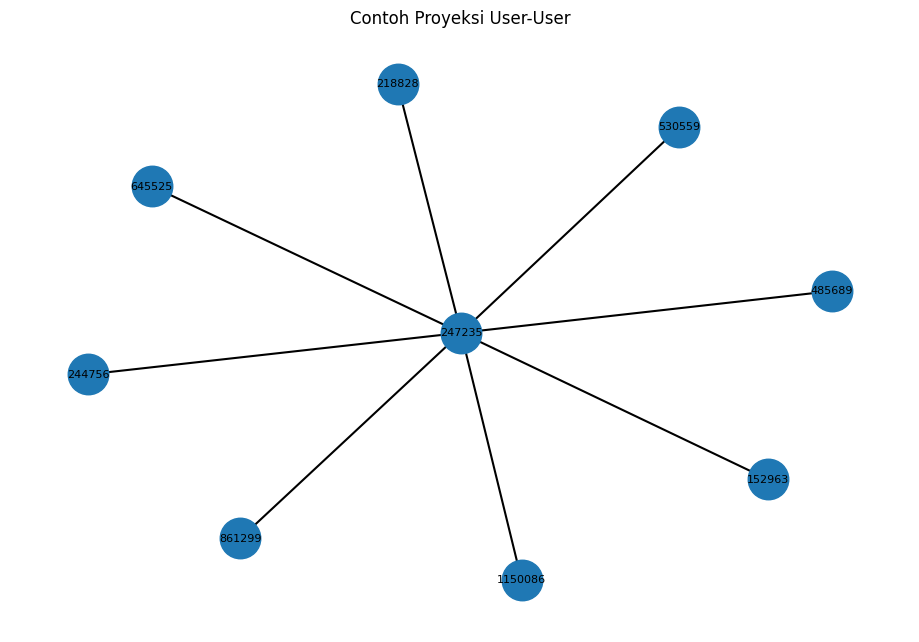

In [20]:
import networkx as nx
import matplotlib.pyplot as plt

# Memilih 40 User dengan jumlah Item unik terbanyak
user_terpilih = np.argsort(item_per_user)[-40:]

# Membuat proyeksi User-User
data_user = vsm_user[user_terpilih]
proyeksi_user = data_user @ data_user.T

# Menghapus hubungan User dengan dirinya sendiri
proyeksi_user.setdiag(0)
proyeksi_user.eliminate_zeros()

# Membuat graf NetworkX
G_user = nx.from_scipy_sparse_array(proyeksi_user)

print("Jumlah node proyeksi:", G_user.number_of_nodes())
print("Jumlah edge proyeksi:", G_user.number_of_edges())

# Memilih User dengan tetangga terbanyak
user_pusat = max(G_user.degree, key=lambda x: x[1])[0]

# Mengambil 8 tetangga dengan bobot hubungan tertinggi
tetangga = sorted(
    G_user[user_pusat],
    key=lambda x: G_user[user_pusat][x]["weight"],
    reverse=True
)[:8]

# Membuat graf kecil untuk ditampilkan
G_tampil = nx.Graph()

for user in tetangga:
    G_tampil.add_edge(user_pusat, user)

# Menggunakan ID User sebagai label
labels = {
    n: str(id_user[user_terpilih[n]])
    for n in G_tampil.nodes()
}

# Menampilkan graf
plt.figure(figsize=(9, 6))
pos = nx.spring_layout(G_tampil, seed=42)

nx.draw(
    G_tampil,
    pos,
    labels=labels,
    with_labels=True,
    node_size=850,
    font_size=8,
    width=1.5
)

plt.title("Contoh Proyeksi User-User")
plt.show()

#### Hasil Proyeksi User–User

Setelah membuat VSM, saya melakukan proyeksi User–User menggunakan NetworkX. Dua User dianggap memiliki hubungan jika pernah berinteraksi dengan Item yang sama. Bobot hubungan menunjukkan jumlah Item yang sama-sama pernah diakses.

Untuk membuat proyeksi, saya memilih 40 User dengan jumlah Item unik terbanyak. Dari proses tersebut, diperoleh graf dengan 40 node dan 297 edge.

Pada visualisasi, saya hanya menampilkan User `247235` dan 8 tetangganya agar gambar lebih mudah dibaca. ID yang ditampilkan pada node merupakan ID User dari dataset RetailRocket.

Hasil ini menunjukkan bahwa hubungan antar-User dapat dibentuk berdasarkan kesamaan Item yang pernah diakses. Namun, graf yang ditampilkan hanya sebagian dari hasil proyeksi, bukan seluruh User pada data P1.

#### 5. Vector Space Modelling (VSM) untuk Item

Pada tahap ini, saya membuat VSM dari sisi Item menggunakan data training P1. Berbeda dengan VSM User sebelumnya, matriks ini menggunakan Item sebagai baris dan User sebagai kolom.

VSM Item dibuat dengan melakukan transpose pada matriks `vsm_user` yang sudah dibuat sebelumnya. Nilai `1` menunjukkan bahwa suatu Item pernah diakses oleh User, sedangkan nilai `0` menunjukkan tidak ada interaksi yang tercatat.

Saya tetap menggunakan `csr_matrix` agar matriks dapat disimpan dan diolah dengan lebih hemat memori.

In [21]:
# Membuat VSM Item dari matriks User-Item
vsm_item = vsm_user.T.tocsr()

# Menghitung karakteristik VSM Item
jumlah_item, jumlah_user = vsm_item.shape

total_elemen_item = jumlah_item * jumlah_user
density_item = (vsm_item.nnz / total_elemen_item) * 100

# Menghitung jumlah User unik pada setiap Item
user_per_item = np.asarray(vsm_item.sum(axis=1)).ravel()

print("Dimensi matriks:", vsm_item.ndim)
print("Shape VSM Item:", vsm_item.shape)
print("Jumlah Item:", jumlah_item)
print("Jumlah User:", jumlah_user)
print("Jumlah nilai bukan nol:", vsm_item.nnz)
print(f"Density matriks: {density_item:.4f}%")
print(f"Rata-rata User per Item: {user_per_item.mean():.2f}")
print("Tipe matriks:", type(vsm_item).__name__)

Dimensi matriks: 2
Shape VSM Item: (51287, 82353)
Jumlah Item: 51287
Jumlah User: 82353
Jumlah nilai bukan nol: 113274
Density matriks: 0.0027%
Rata-rata User per Item: 2.21
Tipe matriks: csr_matrix


#### Karakteristik VSM Item

Dari hasil perhitungan, VSM Item memiliki 2 dimensi dengan `shape` `(51287, 82353)`, yaitu 51.287 Item dan 82.353 User. Jumlah pasangan Item–User yang memiliki interaksi sebanyak 113.274.

Nilai *density* matriks sebesar 0,0027%, sehingga sebagian besar elemennya bernilai `0`. Rata-rata setiap Item diakses oleh 2,21 User unik pada periode P1.

Jumlah nilai bukan nol dan *density* sama seperti VSM User karena matriks ini dibuat dengan melakukan transpose pada `vsm_user`.

Jumlah node proyeksi: 40
Jumlah edge proyeksi: 235


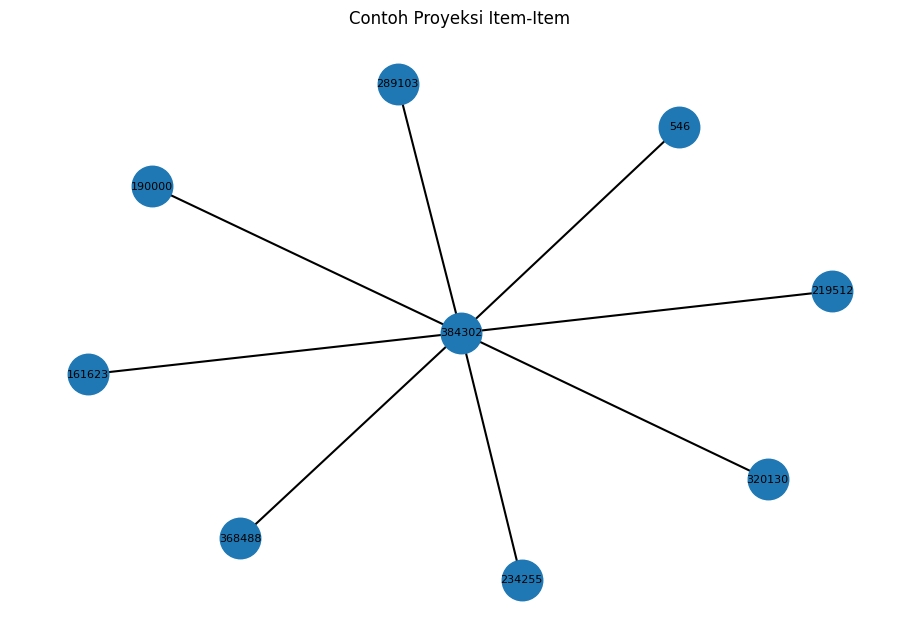

In [22]:
import networkx as nx
import matplotlib.pyplot as plt

# Memilih 40 Item dengan jumlah User unik terbanyak
item_terpilih = np.argsort(user_per_item)[-40:]

# Membuat proyeksi Item-Item
data_item = vsm_item[item_terpilih]
proyeksi_item = data_item @ data_item.T

# Menghapus hubungan Item dengan dirinya sendiri
proyeksi_item.setdiag(0)
proyeksi_item.eliminate_zeros()

# Membuat graf NetworkX
G_item = nx.from_scipy_sparse_array(proyeksi_item)

print("Jumlah node proyeksi:", G_item.number_of_nodes())
print("Jumlah edge proyeksi:", G_item.number_of_edges())

if G_item.number_of_edges() > 0:
    # Memilih Item dengan tetangga terbanyak
    item_pusat = max(G_item.degree, key=lambda x: x[1])[0]

    # Mengambil 8 tetangga dengan bobot tertinggi
    tetangga = sorted(
        G_item[item_pusat],
        key=lambda x: G_item[item_pusat][x]["weight"],
        reverse=True
    )[:8]

    # Membuat graf kecil untuk ditampilkan
    G_tampil_item = nx.Graph()

    for item in tetangga:
        G_tampil_item.add_edge(item_pusat, item)

    # Menggunakan ID Item asli sebagai label
    labels = {
        n: str(id_item[item_terpilih[n]])
        for n in G_tampil_item.nodes()
    }

    # Menampilkan graf
    plt.figure(figsize=(9, 6))
    pos = nx.spring_layout(G_tampil_item, seed=42)

    nx.draw(
        G_tampil_item,
        pos,
        labels=labels,
        with_labels=True,
        node_size=850,
        font_size=8,
        width=1.5
    )

    plt.title("Contoh Proyeksi Item-Item")
    plt.show()

else:
    print("Tidak ada hubungan antar-Item pada sampel ini.")

#### Hasil Proyeksi Item–Item

Setelah membuat VSM Item, saya melakukan proyeksi Item–Item menggunakan NetworkX. Dua Item dianggap memiliki hubungan jika pernah diakses oleh User yang sama. Bobot hubungan menunjukkan jumlah User yang sama-sama mengakses kedua Item tersebut.

Saya memilih 40 Item dengan jumlah User unik terbanyak untuk membuat proyeksi. Dari hasilnya, diperoleh graf dengan 40 node dan 235 edge.

Pada gambar, saya hanya menampilkan Item `384302` dan 8 tetangganya agar graf lebih mudah dibaca. Angka pada setiap node merupakan ID Item dari dataset RetailRocket.

Dari hasil tersebut, hubungan antar-Item dapat dibentuk berdasarkan kesamaan User yang pernah mengaksesnya. Graf yang ditampilkan hanya sebagian dari hasil proyeksi, bukan seluruh Item pada data P1.

#### 6. Perbandingan Proyeksi User–User dan Item–Item

Pada tahap ini, saya membandingkan hasil proyeksi User–User dan Item–Item untuk melihat mana yang lebih efisien dan sesuai untuk proses rekomendasi.

Pada nomor sebelumnya, visualisasi hanya menggunakan 40 User dan 40 Item terpilih. Oleh karena itu, saya melakukan perbandingan kembali menggunakan seluruh matriks VSM P1.

Perbandingan dilakukan berdasarkan jumlah node, jumlah edge, waktu komputasi, dan penggunaan memori. Hasilnya akan digunakan sebagai pertimbangan untuk memilih proyeksi pada perhitungan similarity berikutnya.

In [23]:
import time

# Fungsi untuk menghitung karakteristik proyeksi
def cek_proyeksi(matriks):
    mulai = time.perf_counter()

    hasil = matriks @ matriks.T
    hasil.setdiag(0)
    hasil.eliminate_zeros()

    waktu = time.perf_counter() - mulai

    jumlah_node = hasil.shape[0]
    jumlah_edge = hasil.nnz // 2

    ukuran_memori = (
        hasil.data.nbytes +
        hasil.indices.nbytes +
        hasil.indptr.nbytes
    ) / (1024 ** 2)

    return jumlah_node, jumlah_edge, waktu, ukuran_memori


# Menghitung proyeksi User-User
node_user, edge_user, waktu_user, memori_user = cek_proyeksi(vsm_user)

# Menghitung proyeksi Item-Item
node_item, edge_item, waktu_item, memori_item = cek_proyeksi(vsm_item)

print("Proyeksi User-User")
print("Jumlah node:", node_user)
print("Jumlah edge:", edge_user)
print(f"Waktu komputasi: {waktu_user:.4f} detik")
print(f"Memori matriks: {memori_user:.2f} MB")

print("\nProyeksi Item-Item")
print("Jumlah node:", node_item)
print("Jumlah edge:", edge_item)
print(f"Waktu komputasi: {waktu_item:.4f} detik")
print(f"Memori matriks: {memori_item:.2f} MB")

Proyeksi User-User
Jumlah node: 82353
Jumlah edge: 506557
Waktu komputasi: 0.0418 detik
Memori matriks: 11.91 MB

Proyeksi Item-Item
Jumlah node: 51287
Jumlah edge: 393797
Waktu komputasi: 0.0214 detik
Memori matriks: 9.21 MB


In [24]:
# Mengulang pengukuran waktu sebanyak 5 kali
waktu_user_ulang = []
waktu_item_ulang = []

for i in range(5):
    _, _, t_user, _ = cek_proyeksi(vsm_user)
    _, _, t_item, _ = cek_proyeksi(vsm_item)

    waktu_user_ulang.append(t_user)
    waktu_item_ulang.append(t_item)

print("Rata-rata waktu dari 5 percobaan:")
print(f"User-User: {np.mean(waktu_user_ulang):.4f} detik")
print(f"Item-Item: {np.mean(waktu_item_ulang):.4f} detik")

Rata-rata waktu dari 5 percobaan:
User-User: 0.0246 detik
Item-Item: 0.0160 detik


#### Hasil Perbandingan Proyeksi

Berdasarkan hasil perhitungan menggunakan seluruh data P1, proyeksi User–User menghasilkan 82.353 node dan 506.557 edge. Sementara itu, proyeksi Item–Item menghasilkan 51.287 node dan 393.797 edge.

Dari hasil pengukuran awal, memori matriks proyeksi User–User sebesar 11,91 MB, sedangkan Item–Item sebesar 9,21 MB.

Saya juga mengulangi pengukuran waktu komputasi sebanyak 5 kali. Hasil rata-ratanya adalah 0,0246 detik untuk User–User dan 0,0160 detik untuk Item–Item.

Dari hasil tersebut, saya memilih proyeksi Item–Item karena membutuhkan waktu komputasi lebih singkat dan memori matriks yang lebih kecil pada pengujian ini. Proyeksi Item–Item juga dapat digunakan untuk mencari produk yang mirip berdasarkan User yang pernah mengaksesnya.

Namun, perbandingan ini baru menunjukkan efisiensi komputasi, belum membuktikan bahwa hasil rekomendasinya lebih akurat. Hal tersebut akan diperiksa melalui evaluasi rekomendasi pada tahap berikutnya.

#### 7. Perhitungan Similarity Item–Item

Pada tahap ini, saya menghitung similarity antar-Item menggunakan hasil VSM dan proyeksi Item–Item yang sudah dibuat sebelumnya.

Metode yang digunakan adalah Cosine Similarity. Perhitungan dilakukan berdasarkan kesamaan User yang pernah mengakses setiap Item. Semakin besar nilai similarity, semakin mirip pola interaksi kedua Item tersebut.

Saya menggunakan data training P1 dan tetap memakai sparse matrix agar perhitungan tidak membutuhkan terlalu banyak memori.

In [25]:
import numpy as np
from scipy.sparse import diags

# Menghitung jumlah User unik pada setiap Item
jumlah_user_item = np.asarray(vsm_item.sum(axis=1)).ravel()

# Normalisasi untuk Cosine Similarity
normalisasi = diags(1 / np.sqrt(jumlah_user_item))

# Menghitung similarity Item-Item
similarity_item = normalisasi @ (vsm_item @ vsm_item.T) @ normalisasi
similarity_item = similarity_item.tocsr()

# Menghapus similarity Item dengan dirinya sendiri
similarity_item.setdiag(0)
similarity_item.eliminate_zeros()

print("Shape matriks similarity:", similarity_item.shape)
print("Jumlah pasangan Item yang memiliki similarity:", similarity_item.nnz // 2)

# Memilih Item sebagai acuan
id_acuan = 384302
posisi_item = np.where(id_item == id_acuan)[0][0]

# Mengambil nilai similarity untuk Item acuan
skor_item = similarity_item.getrow(posisi_item)

# Mengambil 5 Item dengan similarity tertinggi
urutan = np.argsort(skor_item.data)[::-1][:5]

top5_item = []

print("\nItem acuan:", id_acuan)
print("5 Item dengan similarity tertinggi:")

for i in urutan:
    item_mirip = int(id_item[skor_item.indices[i]])
    nilai_similarity = float(skor_item.data[i])

    top5_item.append((item_mirip, nilai_similarity))

    print(f"Item {item_mirip}: {nilai_similarity:.4f}")

Shape matriks similarity: (51287, 51287)
Jumlah pasangan Item yang memiliki similarity: 393797

Item acuan: 384302
5 Item dengan similarity tertinggi:
Item 219512: 0.2009
Item 190536: 0.1472
Item 400442: 0.1275
Item 61840: 0.1275
Item 241391: 0.1275


In [26]:
from neo4j import GraphDatabase
from getpass import getpass

# Menyiapkan hasil similarity
data_similarity = []

for item, skor in top5_item:
    data_similarity.append({
        "item": int(item),
        "score": float(skor)
    })

# Menghubungkan Python ke Neo4j
password = getpass("Password Neo4j: ")

driver = GraphDatabase.driver(
    "bolt://127.0.0.1:7687",
    auth=("neo4j", password)
)

try:
    with driver.session(database="neo4j") as session:
        query = """
        UNWIND $data AS row
        MATCH (a:Item {itemId: $acuan})
        MATCH (b:Item {itemId: row.item})
        MERGE (a)-[r:SIMILAR_TO]->(b)
        SET r.score = row.score
        RETURN count(r) AS jumlah
        """

        hasil = session.run(
            query,
            data=data_similarity,
            acuan=int(id_acuan)
        ).single()

        print("Jumlah relationship similarity:", hasil["jumlah"])

finally:
    driver.close()

Password Neo4j:  ········


Jumlah relationship similarity: 5


#### Hasil Perhitungan Similarity

Saya menggunakan Item `384302` sebagai acuan untuk mencari lima Item yang paling mirip. Dari hasil perhitungan Cosine Similarity menggunakan Python, diperoleh hasil berikut:

| Item | Similarity |
|---|---:|
| `219512` | 0.2009 |
| `190536` | 0.1472 |
| `61840` | 0.1275 |
| `241391` | 0.1275 |
| `400442` | 0.1275 |

**a. Query Cypher untuk 5 Item dengan Similarity Tertinggi**

Untuk mengambil lima Item dengan nilai similarity tertinggi, saya menjalankan query berikut di Neo4j:

```cypher
MATCH (a:Item {itemId: 384302})-[r:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan,
       b.itemId AS item_mirip,
       r.score AS similarity
ORDER BY similarity DESC
LIMIT 5;
```

Query `MATCH` digunakan untuk mencari relationship `SIMILAR_TO` dari Item `384302`. Nilai similarity diambil dari properti `r.score`, kemudian diurutkan dari nilai terbesar menggunakan `ORDER BY similarity DESC`. Perintah `LIMIT 5` digunakan untuk menampilkan lima Item teratas.

Hasil query di Neo4j sesuai dengan hasil perhitungan Python.

**b. Menyimpan Nilai Similarity ke Neo4j**

Setelah menghitung similarity menggunakan Python, saya menyimpan lima hasil tersebut ke database Neo4j. Relationship yang digunakan adalah `SIMILAR_TO`, sedangkan nilai kemiripannya disimpan pada properti `score`.

Penyimpanan dilakukan menggunakan `MERGE` agar hubungan yang sama tidak dibuat berulang. Dari hasil program, terdapat 5 relationship similarity yang berhasil disimpan.

Jumlah seluruh relationship pada database juga bertambah dari 141.416 menjadi 141.421.

#### 8. Graf Sebelum dan Sesudah Similarity

Pada tahap ini, saya membandingkan graf sebelum dan sesudah nilai similarity ditambahkan ke Neo4j. Perbandingan dilakukan menggunakan Item `384302` sebagai acuan dan lima Item yang memiliki similarity tertinggi.

**a. Graf Sebelum Similarity**

Sebelum menyimpan hasil similarity, saya menjalankan query berikut di Neo4j:

```cypher
MATCH (i:Item)
WHERE i.itemId IN [384302, 219512, 190536, 400442, 61840, 241391]
OPTIONAL MATCH (i)-[r:SIMILAR_TO]->(j:Item)
WHERE j.itemId IN [384302, 219512, 190536, 400442, 61840, 241391]
RETURN i, r, j;
```

Hasil query sebelum penambahan similarity menunjukkan enam node `Item` yang belum memiliki relationship `SIMILAR_TO`.

![Graf Sebelum Similarity](graf_sebelum_similarity.png)

**b. Graf Sesudah Similarity**

Setelah nilai Cosine Similarity disimpan melalui Python, saya menjalankan query berikut untuk melihat hubungan yang sudah terbentuk:

```cypher
MATCH p = (a:Item {itemId: 384302})-[r:SIMILAR_TO]->(b:Item)
RETURN p
ORDER BY r.score DESC
LIMIT 5;
```

Hasilnya menunjukkan Item `384302` terhubung dengan lima Item lainnya melalui relationship `SIMILAR_TO`.

![Graf Sesudah Similarity](graf_sesudah_similarity.png)

**c. Perbandingan Hasil**

Sebelum similarity ditambahkan, keenam Item belum memiliki hubungan `SIMILAR_TO`. Setelah proses penyimpanan, terbentuk lima relationship baru dari Item `384302` menuju Item `219512`, `190536`, `61840`, `241391`, dan `400442`.

Setiap relationship memiliki properti `score` yang berisi nilai Cosine Similarity. Jumlah relationship dalam database juga bertambah dari 141.416 menjadi 141.421.

Dari hasil tersebut, nilai similarity yang dihitung menggunakan Python sudah berhasil disimpan dan ditampilkan kembali sebagai hubungan antar-Item di Neo4j.

### 2.2 Analytics

#### 1. Pemilihan User dan Rekomendasi KNN

Pemilihan User dilakukan secara acak menggunakan `seed = 185` dari 1.026 User yang memiliki minimal dua Item unik pada P1 dan masih memiliki aktivitas pada P2.

Kriteria tersebut digunakan agar User terpilih memiliki riwayat interaksi untuk membuat rekomendasi dan aktivitas pada periode testing untuk evaluasi. Data P2 hanya digunakan untuk menentukan calon User dan mengevaluasi hasil, sedangkan perhitungan similarity serta rekomendasi tetap menggunakan data P1.

Dengan demikian, pemilihan dilakukan secara acak dari kelompok User yang memenuhi kriteria, bukan dari seluruh User dalam dataset.

Dari proses tersebut, diperoleh User `382867` yang memiliki 2 Item unik pada P1 dan 4 interaksi pada P2.

In [32]:
# Membaca data testing P2
data_p2 = pd.read_csv(
    "dataset/hasil_filter/events_p2_test.csv",
    usecols=["visitorid", "itemid"]
)

# Menghitung jumlah Item unik setiap User pada P1
jumlah_item_user = data_unik.groupby("visitorid")["itemid"].nunique()

# Memilih User dengan minimal 2 Item pada P1
user_p1 = jumlah_item_user[jumlah_item_user >= 2].index

# Mengambil User yang juga aktif pada P2
user_p2 = data_p2["visitorid"].unique()
calon_user = sorted(set(user_p1) & set(user_p2))

# Memilih satu User secara acak
seed = 185
rng = np.random.default_rng(seed)
user_pilihan = int(rng.choice(calon_user))

print("Seed:", seed)
print("Jumlah calon User:", len(calon_user))
print("User terpilih:", user_pilihan)
print("Jumlah Item unik P1:", jumlah_item_user.loc[user_pilihan])
print("Jumlah interaksi P2:",
      len(data_p2[data_p2["visitorid"] == user_pilihan]))

Seed: 185
Jumlah calon User: 1026
User terpilih: 382867
Jumlah Item unik P1: 2
Jumlah interaksi P2: 4


##### a. Skrip Python untuk Rekomendasi KNN

Saya menggunakan Item-Based KNN dengan `k = 5` untuk membuat rekomendasi kepada User `382867`. Metode ini mencari lima Item yang paling mirip dengan setiap Item yang pernah diakses User pada P1.

Nilai kemiripan diambil dari matriks `similarity_item` yang sebelumnya sudah dihitung menggunakan Cosine Similarity. Jika suatu Item muncul sebagai kandidat dari beberapa Item, skornya dijumlahkan.

Item yang sudah pernah diakses User pada P1 tidak dimasukkan ke daftar rekomendasi. Setelah itu, kandidat diurutkan berdasarkan skor tertinggi.

In [33]:
# Menentukan jumlah tetangga KNN
k = 5

# Mencari posisi User terpilih pada VSM
posisi_user = np.where(id_user == user_pilihan)[0][0]

# Mengambil Item yang pernah diakses User pada P1
item_user = vsm_user.getrow(posisi_user).indices
item_sudah_dilihat = set(item_user)

# Menyimpan skor kandidat rekomendasi
skor_rekomendasi = {}

for item in item_user:
    # Mengambil similarity milik Item
    tetangga = similarity_item.getrow(item)

    # Memilih 5 Item dengan similarity tertinggi
    urutan = np.argsort(tetangga.data)[::-1][:k]

    for i in urutan:
        item_mirip = int(tetangga.indices[i])
        skor = float(tetangga.data[i])

        # Tidak merekomendasikan Item yang sudah diakses
        if item_mirip not in item_sudah_dilihat:
            skor_rekomendasi[item_mirip] = (
                skor_rekomendasi.get(item_mirip, 0) + skor
            )

# Mengurutkan kandidat berdasarkan skor
hasil_urut = sorted(
    skor_rekomendasi.items(),
    key=lambda x: (-x[1], int(id_item[x[0]]))
)

# Mengambil 5 rekomendasi teratas
top5_rekomendasi = [
    (int(id_item[item]), skor)
    for item, skor in hasil_urut[:5]
]

print("User terpilih:", user_pilihan)
print("Item yang pernah diakses pada P1:")
print([int(id_item[i]) for i in item_user])

print("\n5 rekomendasi teratas:")
for nomor, (item, skor) in enumerate(top5_rekomendasi, start=1):
    print(f"{nomor}. Item {item} - Skor {skor:.4f}")

print("\n3 Item yang direkomendasikan:")
for item, skor in top5_rekomendasi[:3]:
    print(f"Item {item}")

User terpilih: 382867
Item yang pernah diakses pada P1:
[304537, 453618]

5 rekomendasi teratas:
1. Item 85614 - Skor 0.2294
2. Item 200356 - Skor 0.2294
3. Item 205644 - Skor 0.2294
4. Item 283816 - Skor 0.2294
5. Item 379796 - Skor 0.2294

3 Item yang direkomendasikan:
Item 85614
Item 200356
Item 205644


##### b. Tiga Item yang Diiklankan untuk k = 5

Berdasarkan hasil Item-Based KNN dengan `k = 5`, saya mendapatkan lima rekomendasi teratas untuk User `382867` sebagai berikut:

| Peringkat | Item | Skor |
|---|---|---:|
| 1 | `85614` | 0.2294 |
| 2 | `200356` | 0.2294 |
| 3 | `205644` | 0.2294 |
| 4 | `283816` | 0.2294 |
| 5 | `379796` | 0.2294 |

Dari lima hasil tersebut, tiga Item yang dipilih untuk diiklankan adalah `85614`, `200356`, dan `205644`.

Kelima kandidat memiliki skor yang sama setelah dibulatkan menjadi empat angka desimal. Item yang sudah pernah diakses User pada P1 tidak dimasukkan ke daftar rekomendasi.

In [30]:
# Mengambil Item User terpilih pada data testing P2
item_test = set(
    data_p2[data_p2["visitorid"] == user_pilihan]["itemid"]
)

# Mengambil Item yang sudah diakses pada training P1
item_train = set(int(id_item[i]) for i in item_user)

# Item baru yang diakses User pada P2
item_relevan = item_test - item_train

# Mengambil ID dari 5 rekomendasi
item_rekomendasi = [item for item, skor in top5_rekomendasi]

print("User:", user_pilihan)
print("Item P1:", sorted(item_train))
print("Item P2:", sorted(item_test))
print("Item baru pada P2:", sorted(item_relevan))
print("5 Item rekomendasi:", item_rekomendasi)

# Membandingkan rekomendasi dengan Item baru pada P2
item_cocok = set(item_rekomendasi) & item_relevan

print("Item rekomendasi yang cocok:", sorted(item_cocok))

User: 382867
Item P1: [304537, 453618]
Item P2: [98691, 103222, 111417, 361427]
Item baru pada P2: [98691, 103222, 111417, 361427]
5 Item rekomendasi: [85614, 200356, 205644, 283816, 379796]
Item rekomendasi yang cocok: []


#### 2. Evaluasi Hasil Rekomendasi

Setelah mendapatkan lima rekomendasi, saya membandingkannya dengan data testing P2 untuk melihat apakah ada Item yang sesuai dengan aktivitas User `382867`.

Evaluasi menggunakan Item baru yang diakses User pada P2. Hasil pemeriksaan ini digunakan untuk menghitung `Hit@5` dan `NDCG@5`.

##### a. Perhitungan Hit@5

Metrik `Hit@5` digunakan untuk melihat apakah terdapat minimal satu Item yang relevan dari lima rekomendasi teratas.

Nilai `Hit@5` adalah `1` jika ada Item rekomendasi yang cocok dengan data testing P2, dan `0` jika tidak ada yang cocok.

Pada perhitungan ini, Item dianggap relevan jika merupakan Item baru yang diakses User pada P2.

In [34]:
# Mengambil 5 rekomendasi teratas
rekomendasi_5 = item_rekomendasi[:5]

# Menghitung Hit@5
hit_at_5 = 0

for item in rekomendasi_5:
    if item in item_relevan:
        hit_at_5 = 1
        break

print("User:", user_pilihan)
print("5 rekomendasi:", rekomendasi_5)
print("Item relevan pada P2:", sorted(item_relevan))
print("Hit@5:", hit_at_5)

User: 382867
5 rekomendasi: [85614, 200356, 205644, 283816, 379796]
Item relevan pada P2: [98691, 103222, 111417, 361427]
Hit@5: 0


##### b. Perhitungan NDCG@5

Metrik `NDCG@5` digunakan untuk menilai urutan lima rekomendasi berdasarkan relevansinya terhadap data testing.

Setiap Item diberi nilai relevansi `1` jika cocok dengan Item baru pada P2 dan `0` jika tidak cocok.

Perhitungan dilakukan dengan mencari nilai `DCG@5`, kemudian membaginya dengan `IDCG@5`, yaitu nilai DCG terbaik yang mungkin diperoleh. Item relevan pada peringkat atas akan memberikan nilai lebih besar.

In [36]:
# Menentukan relevansi setiap rekomendasi
relevansi = []

for item in rekomendasi_5:
    if item in item_relevan:
        relevansi.append(1)
    else:
        relevansi.append(0)

# Menghitung DCG@5
dcg_at_5 = 0

for i, nilai in enumerate(relevansi):
    dcg_at_5 += nilai / np.log2(i + 2)

# Menghitung IDCG@5
jumlah_relevan = min(len(item_relevan), 5)
idcg_at_5 = 0

for i in range(jumlah_relevan):
    idcg_at_5 += 1 / np.log2(i + 2)

# Menghitung NDCG@5
if idcg_at_5 > 0:
    ndcg_at_5 = dcg_at_5 / idcg_at_5
else:
    ndcg_at_5 = 0

print("Relevansi:", relevansi)
print(f"DCG@5: {dcg_at_5:.4f}")
print(f"IDCG@5: {idcg_at_5:.4f}")
print(f"NDCG@5: {ndcg_at_5:.4f}")

Relevansi: [0, 0, 0, 0, 0]
DCG@5: 0.0000
IDCG@5: 2.5616
NDCG@5: 0.0000


#### Hasil Evaluasi Rekomendasi

**a. Hasil Hit@5**

Berdasarkan hasil pengujian, nilai `Hit@5` yang diperoleh adalah `0`. Hal ini karena tidak ada Item dari lima rekomendasi teratas yang cocok dengan Item baru yang diakses User `382867` pada P2.

**b. Hasil NDCG@5**

Hasil perhitungan menunjukkan nilai `DCG@5` sebesar `0`, sedangkan `IDCG@5` sebesar `2.5616`. Dengan demikian, nilai `NDCG@5` yang diperoleh adalah `0.0000`.

Nilai tersebut diperoleh karena seluruh Item rekomendasi memiliki nilai relevansi `0`, sehingga tidak ada Item relevan yang ditemukan pada lima peringkat teratas.

Dari hasil evaluasi ini, rekomendasi Item-Based KNN dengan `k = 5` belum berhasil menemukan Item yang relevan untuk User `382867` pada periode testing P2. Namun, hasil ini hanya berdasarkan pengujian terhadap satu User, sehingga belum dapat menggambarkan performa rekomendasi secara keseluruhan.

#### Pemeriksaan Tambahan Hasil Evaluasi

Saya melakukan pemeriksaan tambahan untuk mengetahui mengapa nilai `Hit@5` dan `NDCG@5` sama-sama `0`.

Pemeriksaan dilakukan dengan melihat apakah Item relevan pada P2 tersedia dalam data training P1 dan menghitung nilai similarity antara Item riwayat User dengan Item relevan tersebut.

In [37]:
# Mengambil semua Item yang tersedia pada training P1
item_tersedia_p1 = set(int(item) for item in id_item)

# Memeriksa Item relevan pada P2
item_ada_di_p1 = item_relevan & item_tersedia_p1
item_tidak_ada_di_p1 = item_relevan - item_tersedia_p1

print("User:", user_pilihan)
print("Item baru pada P2:", sorted(item_relevan))

print("\nItem P2 yang tersedia di P1:")
print(sorted(item_ada_di_p1))

print("\nItem P2 yang tidak tersedia di P1:")
print(sorted(item_tidak_ada_di_p1))

print("\nJumlah Item relevan:", len(item_relevan))
print("Jumlah yang tersedia di P1:", len(item_ada_di_p1))

User: 382867
Item baru pada P2: [98691, 103222, 111417, 361427]

Item P2 yang tersedia di P1:
[98691, 103222, 111417, 361427]

Item P2 yang tidak tersedia di P1:
[]

Jumlah Item relevan: 4
Jumlah yang tersedia di P1: 4


In [38]:
# Memeriksa similarity Item P1 dengan Item relevan P2
print("User:", user_pilihan)
print("Item P1:", sorted(item_train))
print("Item relevan P2:", sorted(item_relevan))

print("\nSimilarity Item P1 dengan Item relevan P2:")

for item_awal in sorted(item_train):
    posisi_awal = np.where(id_item == item_awal)[0][0]

    for item_tujuan in sorted(item_relevan):
        posisi_tujuan = np.where(id_item == item_tujuan)[0][0]

        skor = float(similarity_item[posisi_awal, posisi_tujuan])

        print(f"Item {item_awal} -> Item {item_tujuan}: {skor:.4f}")

User: 382867
Item P1: [304537, 453618]
Item relevan P2: [98691, 103222, 111417, 361427]

Similarity Item P1 dengan Item relevan P2:
Item 304537 -> Item 98691: 0.0000
Item 304537 -> Item 103222: 0.0000
Item 304537 -> Item 111417: 0.0000
Item 304537 -> Item 361427: 0.0000
Item 453618 -> Item 98691: 0.0000
Item 453618 -> Item 103222: 0.0000
Item 453618 -> Item 111417: 0.0000
Item 453618 -> Item 361427: 0.0000


In [40]:
# Memeriksa apakah similarity benar-benar nol
jumlah_nol = 0

for item_awal in sorted(item_train):
    posisi_awal = np.where(id_item == item_awal)[0][0]

    for item_tujuan in sorted(item_relevan):
        posisi_tujuan = np.where(id_item == item_tujuan)[0][0]
        skor = float(similarity_item[posisi_awal, posisi_tujuan])

        if skor == 0:
            jumlah_nol += 1

print("Jumlah pasangan yang diperiksa:", len(item_train) * len(item_relevan))
print("Jumlah pasangan dengan similarity tepat 0:", jumlah_nol)

Jumlah pasangan yang diperiksa: 8
Jumlah pasangan dengan similarity tepat 0: 8


#### Kesimpulan Pemeriksaan Tambahan

Hasil pemeriksaan menunjukkan bahwa keempat Item relevan pada P2 sudah tersedia dalam data training P1. Namun, seluruh delapan pasangan antara Item riwayat User dan Item relevan memiliki nilai Cosine Similarity tepat `0`.

Artinya, pasangan Item tersebut tidak memiliki User pengakses yang sama pada P1. Hal ini membantu menjelaskan mengapa metode Item-Based KNN belum berhasil merekomendasikan Item yang relevan untuk User `382867`.

Hasil ini hanya berlaku untuk User yang diuji dan belum dapat digunakan untuk menyimpulkan performa model secara keseluruhan.